<a href="https://colab.research.google.com/github/shaikhuzair632-dev/Energy-IESO-Markets-Project-/blob/main/Energy_Market_Forecast_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install -q holidays

from google.colab import drive
drive.mount('/content/drive')

import os
project = "/content/drive/MyDrive/ontario_energy_analytics"
for folder in ["data/raw/ieso_demand", "data/raw/ieso_price", "data/processed", "plots", "models"]:
    os.makedirs(f"{project}/{folder}", exist_ok=True)
print("Ready:", project)

Mounted at /content/drive
Ready: /content/drive/MyDrive/ontario_energy_analytics


In [3]:
import urllib.request

datasets = [
    ("Demand", "PUB_Demand_", "ieso_demand"),
    ("PriceHOEPPredispOR", "PUB_PriceHOEPPredispOR_", "ieso_price"),
]

for ieso_folder, prefix, save_folder in datasets:
    for year in range(2002, 2026):
        file_name = f"{prefix}{year}.csv"
        url = f"https://reports-public.ieso.ca/public/{ieso_folder}/{file_name}"
        save_path = f"{project}/data/raw/{save_folder}/{file_name}"

        if os.path.exists(save_path):
            continue  # already downloaded
        try:
            urllib.request.urlretrieve(url, save_path)
            print("Downloaded", file_name)
        except Exception:
            print("FAILED", file_name)

Downloaded PUB_Demand_2002.csv
Downloaded PUB_Demand_2003.csv
Downloaded PUB_Demand_2004.csv
Downloaded PUB_Demand_2005.csv
Downloaded PUB_Demand_2006.csv
Downloaded PUB_Demand_2007.csv
Downloaded PUB_Demand_2008.csv
Downloaded PUB_Demand_2009.csv
Downloaded PUB_Demand_2010.csv
Downloaded PUB_Demand_2011.csv
Downloaded PUB_Demand_2012.csv
Downloaded PUB_Demand_2013.csv
Downloaded PUB_Demand_2014.csv
Downloaded PUB_Demand_2015.csv
Downloaded PUB_Demand_2016.csv
Downloaded PUB_Demand_2017.csv
Downloaded PUB_Demand_2018.csv
Downloaded PUB_Demand_2019.csv
Downloaded PUB_Demand_2020.csv
Downloaded PUB_Demand_2021.csv
Downloaded PUB_Demand_2022.csv
Downloaded PUB_Demand_2023.csv
Downloaded PUB_Demand_2024.csv
Downloaded PUB_Demand_2025.csv
Downloaded PUB_PriceHOEPPredispOR_2002.csv
Downloaded PUB_PriceHOEPPredispOR_2003.csv
Downloaded PUB_PriceHOEPPredispOR_2004.csv
Downloaded PUB_PriceHOEPPredispOR_2005.csv
Downloaded PUB_PriceHOEPPredispOR_2006.csv
Downloaded PUB_PriceHOEPPredispOR_2007.cs

In [4]:
import glob
import pandas as pd


def read_ieso_file(path):
    """IESO adds note lines on top, so find the real header row."""
    with open(path) as f:
        lines = f.readlines()
    header_row = 0
    for i, line in enumerate(lines):
        if line.strip().lower().startswith("date"):
            header_row = i
            break
    df = pd.read_csv(path, skiprows=header_row)
    df.columns = [c.strip() for c in df.columns]
    return df


def read_all(folder, pattern, value_column, new_name):
    frames = []
    for path in sorted(glob.glob(f"{project}/data/raw/{folder}/{pattern}")):
        df = read_ieso_file(path)[["Date", "Hour", value_column]]
        df.columns = ["date", "hour", new_name]
        frames.append(df)
    return pd.concat(frames, ignore_index=True)


demand = read_all("ieso_demand", "PUB_Demand_????.csv", "Ontario Demand", "hourly_demand")
price = read_all("ieso_price", "PUB_PriceHOEPPredispOR_????.csv", "HOEP", "hourly_average_price")

demand["hourly_demand"] = pd.to_numeric(demand["hourly_demand"], errors="coerce")
price["hourly_average_price"] = pd.to_numeric(price["hourly_average_price"], errors="coerce")

master = demand.merge(price, on=["date", "hour"], how="left")
master = master.dropna(subset=["hourly_demand"]).drop_duplicates(subset=["date", "hour"])

master["hourly_demand"] = master["hourly_demand"] * 1000              # MW -> kWh
master["hourly_average_price"] = master["hourly_average_price"] * 0.1  # $/MWh -> cents/kWh

master["date"] = pd.to_datetime(master["date"])
master = master.sort_values(["date", "hour"])
master.to_csv(f"{project}/data/processed/ontario_hourly_master.csv", index=False)

print("Saved", len(master), "rows,", master["date"].min().date(), "to", master["date"].max().date())
master.head()

Saved 207503 rows, 2002-05-01 to 2025-12-31


,date,hour,hourly_demand,hourly_average_price
0,2002-05-01,1,14137000,2.297
1,2002-05-01,2,13872000,2.327
2,2002-05-01,3,13820000,2.454
3,2002-05-01,4,13744000,1.517
4,2002-05-01,5,14224000,2.359


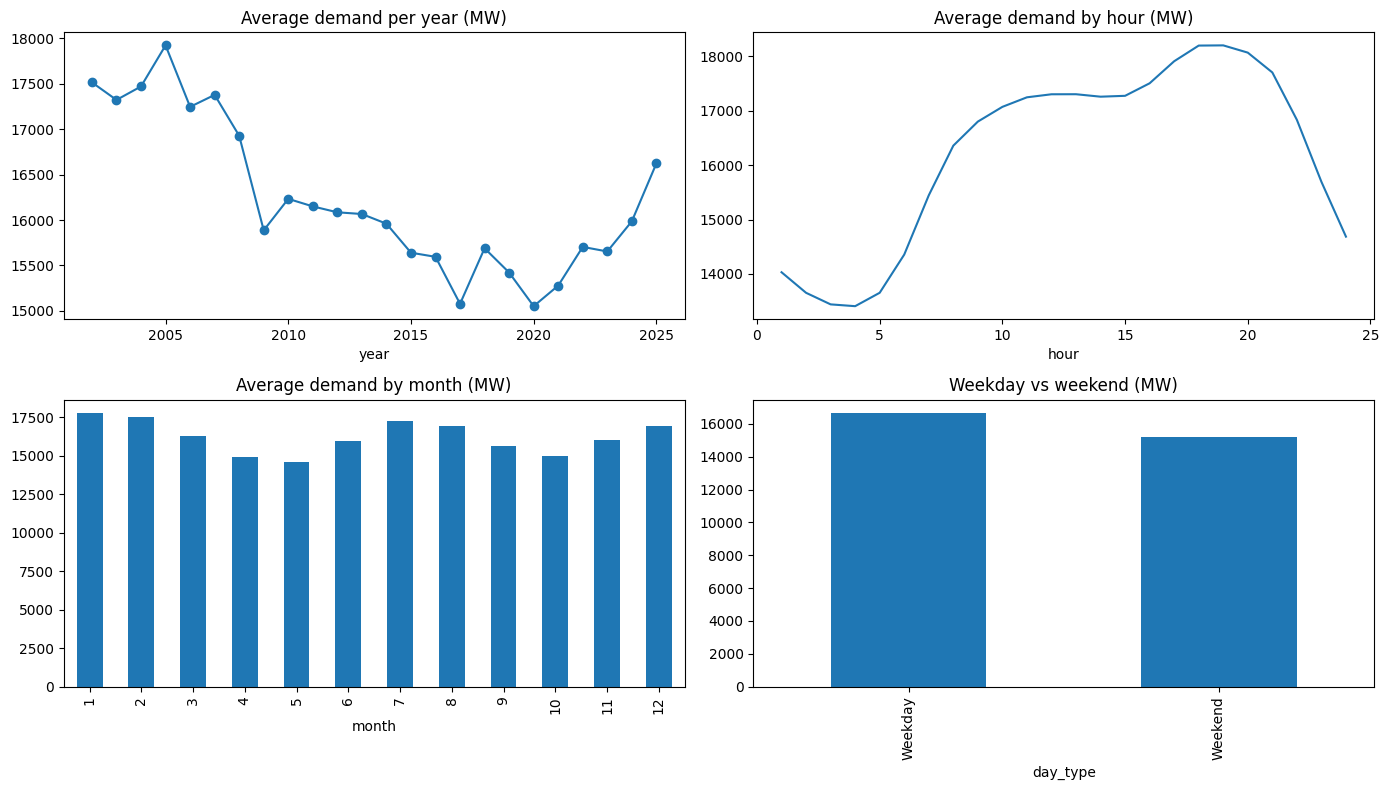

Peak demand: 27005 MW on 2006-08-01


In [5]:
import matplotlib.pyplot as plt

df = pd.read_csv(f"{project}/data/processed/ontario_hourly_master.csv", parse_dates=["date"])
df["demand_mw"] = df["hourly_demand"] / 1000
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["day_type"] = df["date"].dt.dayofweek.apply(lambda d: "Weekend" if d >= 5 else "Weekday")

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
df.groupby("year")["demand_mw"].mean().plot(ax=axes[0, 0], marker="o", title="Average demand per year (MW)")
df.groupby("hour")["demand_mw"].mean().plot(ax=axes[0, 1], title="Average demand by hour (MW)")
df.groupby("month")["demand_mw"].mean().plot(kind="bar", ax=axes[1, 0], title="Average demand by month (MW)")
df.groupby("day_type")["demand_mw"].mean().plot(kind="bar", ax=axes[1, 1], title="Weekday vs weekend (MW)")
plt.tight_layout()
plt.savefig(f"{project}/plots/explore.png")
plt.show()

print("Peak demand:", round(df["demand_mw"].max()), "MW on", df.loc[df["demand_mw"].idxmax(), "date"].date())

   test_year       MAE      RMSE     R2
0       2021  1044.854  1428.977  0.615
1       2022  1008.752  1313.589  0.676
2       2023   816.870  1088.843  0.743
3       2024   958.978  1301.334  0.673
4       2024  1054.177  1403.184  0.673

Average:
 MAE      976.726
RMSE    1307.185
R2         0.676
dtype: float64


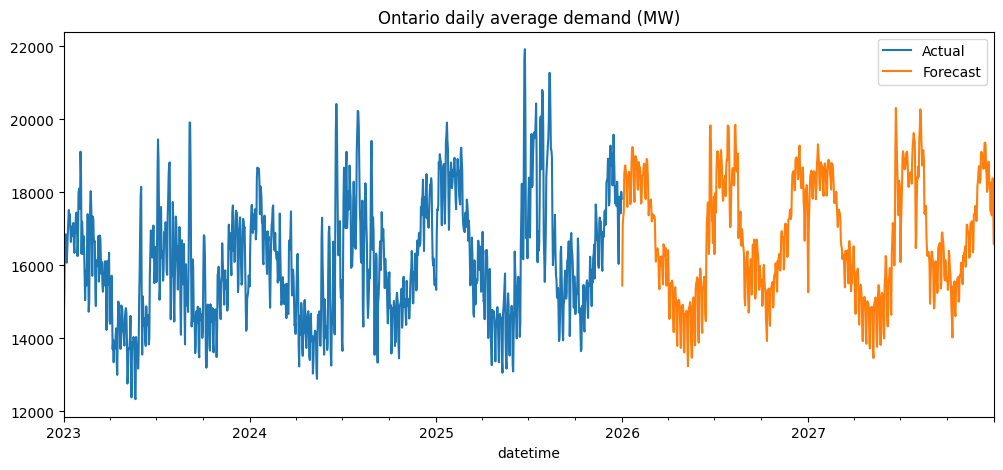

In [6]:
import numpy as np
import holidays
from xgboost import XGBRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Load (IESO hours go 1-24, so subtract 1 to get 0-23)
df = pd.read_csv(f"{project}/data/processed/ontario_hourly_master.csv")
df["datetime"] = pd.to_datetime(df["date"]) + pd.to_timedelta(df["hour"] - 1, unit="h")
df = df.drop_duplicates("datetime").set_index("datetime").sort_index()
df["demand"] = df["hourly_demand"] / 1000  # back to MW
df = df[["demand"]]

# 2. Features
ontario_holidays = holidays.Canada(prov="ON", years=range(2002, 2029))

def add_features(data):
    data = data.copy()
    data["hour"] = data.index.hour
    data["weekday"] = data.index.dayofweek
    data["month"] = data.index.month
    data["year"] = data.index.year
    data["dayofyear"] = data.index.dayofyear
    data["is_holiday"] = [1 if d in ontario_holidays else 0 for d in data.index.date]
    return data

def add_lags(data):
    lookup = data["demand"].to_dict()
    for i, days in enumerate([364, 728, 1092], start=1):
        data[f"lag{i}"] = (data.index - pd.Timedelta(days=days)).map(lookup)
    return data

features = ["hour", "weekday", "month", "year", "dayofyear", "is_holiday", "lag1", "lag2", "lag3"]
data = add_lags(add_features(df)).dropna(subset=["lag1"])

def new_model():
    return XGBRegressor(n_estimators=500, max_depth=6, learning_rate=0.05, random_state=42)

# 3. Test the model (always train on the past, test on the future)
splitter = TimeSeriesSplit(n_splits=5, test_size=24 * 365, gap=24)
results = []
for train_rows, test_rows in splitter.split(data):
    train, test = data.iloc[train_rows], data.iloc[test_rows]
    model = new_model().fit(train[features], train["demand"])
    predicted = model.predict(test[features])
    results.append({
        "test_year": test.index.year.min(),
        "MAE": mean_absolute_error(test["demand"], predicted),
        "RMSE": np.sqrt(mean_squared_error(test["demand"], predicted)),
        "R2": r2_score(test["demand"], predicted),
    })
results = pd.DataFrame(results)
print(results.round(3))
print("\nAverage:\n", results[["MAE", "RMSE", "R2"]].mean().round(3))

# 4. Train on everything and save
final_model = new_model().fit(data[features], data["demand"])
final_model.save_model(f"{project}/models/demand_model.json")

# 5. Forecast one year at a time (2027 uses the 2026 predictions)
future_times = pd.date_range(df.index.max() + pd.Timedelta(hours=1), "2027-12-31 23:00", freq="h")
all_data = pd.concat([df, pd.DataFrame(index=future_times, columns=["demand"], dtype=float)])
all_data = add_features(all_data)

for year in sorted(set(future_times.year)):
    all_data = add_lags(all_data)
    rows = all_data.index.isin(future_times) & (all_data.index.year == year)
    all_data.loc[rows, "demand"] = final_model.predict(all_data.loc[rows, features])

forecast = all_data.loc[future_times, ["demand"]].rename(columns={"demand": "forecast_mw"})
forecast.to_csv(f"{project}/data/processed/forecast_2026_2027.csv")

# 6. Chart
df["demand"].resample("D").mean().loc["2023":].plot(label="Actual", figsize=(12, 5))
forecast["forecast_mw"].resample("D").mean().plot(label="Forecast")
plt.title("Ontario daily average demand (MW)")
plt.legend()
plt.savefig(f"{project}/plots/forecast.png")
plt.show()

In [7]:
import sqlite3
import pandas as pd

df = pd.read_csv(f"{project}/data/processed/ontario_hourly_master.csv")

conn = sqlite3.connect(f"{project}/ontario_energy.db")
df.to_sql("demand_price", conn, if_exists="replace", index=False)

# A "view" is a saved query that gives us friendlier columns (demand in MW, year, month, weekday)
conn.execute("DROP VIEW IF EXISTS hourly")
conn.execute("""
CREATE VIEW hourly AS
SELECT date, hour,
       hourly_demand / 1000.0 AS demand_mw,
       hourly_average_price   AS price_cents,
       CAST(strftime('%Y', date) AS INT) AS year,
       CAST(strftime('%m', date) AS INT) AS month,
       CAST(strftime('%w', date) AS INT) AS dow      -- 0 = Sunday, 6 = Saturday
FROM demand_price
""")
print("Database ready")

Database ready


In [8]:
query = """
SELECT year,
       ROUND(MAX(demand_mw))  AS peak_mw,
       ROUND(AVG(demand_mw))  AS avg_mw,
       ROUND(MAX(demand_mw) * 1.0 / AVG(demand_mw), 2) AS peak_to_avg_ratio
FROM hourly
GROUP BY year
ORDER BY year
"""
pd.read_sql(query, conn)

,year,peak_mw,avg_mw,peak_to_avg_ratio
0,2002,25414.0,17512.0,1.45
1,2003,24753.0,17320.0,1.43
2,2004,24979.0,17468.0,1.43
3,2005,26160.0,17919.0,1.46
4,2006,27005.0,17244.0,1.57
5,2007,25737.0,17375.0,1.48
6,2008,24195.0,16926.0,1.43
7,2009,24380.0,15886.0,1.53
8,2010,25075.0,16232.0,1.54
9,2011,25450.0,16150.0,1.58


In [9]:
query = """
SELECT year,
       ROUND(MAX(demand_mw))  AS peak_mw,
       ROUND(AVG(demand_mw))  AS avg_mw,
       ROUND(MAX(demand_mw) * 1.0 / AVG(demand_mw), 2) AS peak_to_avg_ratio
FROM hourly
GROUP BY year
ORDER BY year
"""
pd.read_sql(query, conn)

,year,peak_mw,avg_mw,peak_to_avg_ratio
0,2002,25414.0,17512.0,1.45
1,2003,24753.0,17320.0,1.43
2,2004,24979.0,17468.0,1.43
3,2005,26160.0,17919.0,1.46
4,2006,27005.0,17244.0,1.57
5,2007,25737.0,17375.0,1.48
6,2008,24195.0,16926.0,1.43
7,2009,24380.0,15886.0,1.53
8,2010,25075.0,16232.0,1.54
9,2011,25450.0,16150.0,1.58


,hour,avg_mw
0,1,14032.0
1,2,13653.0
2,3,13441.0
3,4,13407.0
4,5,13654.0
5,6,14356.0
6,7,15446.0
7,8,16360.0
8,9,16802.0
9,10,17074.0


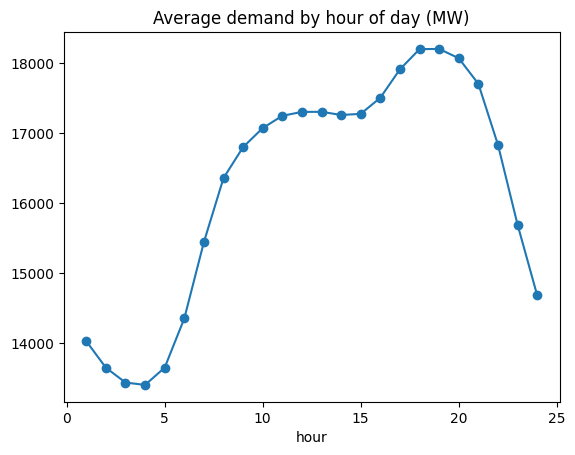

In [10]:
query = """
SELECT hour, ROUND(AVG(demand_mw)) AS avg_mw
FROM hourly
GROUP BY hour
ORDER BY hour
"""
hourly = pd.read_sql(query, conn)
hourly.plot(x="hour", y="avg_mw", kind="line", marker="o", title="Average demand by hour of day (MW)", legend=False)
hourly

,season,avg_mw,peak_mw
0,Fall,15532.0,25062.0
1,Spring,15283.0,24857.0
2,Summer,16717.0,27005.0
3,Winter,17395.0,24979.0


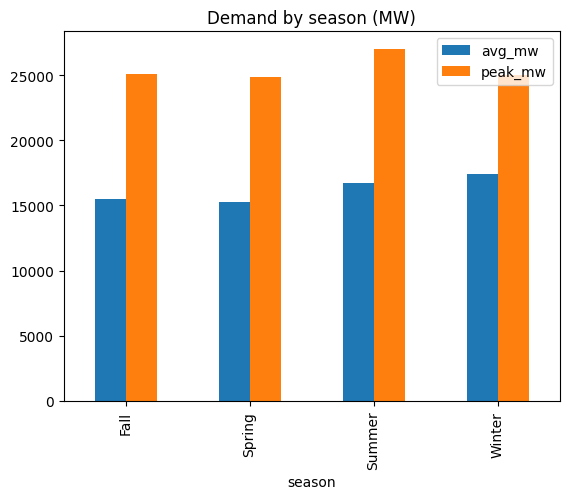

In [11]:
query = """
SELECT CASE WHEN month IN (12, 1, 2) THEN 'Winter'
            WHEN month IN (3, 4, 5)  THEN 'Spring'
            WHEN month IN (6, 7, 8)  THEN 'Summer'
            ELSE 'Fall' END AS season,
       ROUND(AVG(demand_mw)) AS avg_mw,
       ROUND(MAX(demand_mw)) AS peak_mw
FROM hourly
GROUP BY season
"""
season = pd.read_sql(query, conn)
season.plot(x="season", y=["avg_mw", "peak_mw"], kind="bar", title="Demand by season (MW)")
season

In [12]:
query = """
SELECT CASE WHEN dow IN (0, 6) THEN 'Weekend' ELSE 'Weekday' END AS day_type,
       ROUND(AVG(demand_mw)) AS avg_mw,
       ROUND(AVG(price_cents), 2) AS avg_price_cents
FROM hourly
GROUP BY day_type
"""
pd.read_sql(query, conn)

,day_type,avg_mw,avg_price_cents
0,Weekday,16630.0,3.56
1,Weekend,15219.0,2.95


,year,avg_price,min_price,max_price,negative_price_hours
0,2002,5.18,0.78,91.22,0
1,2003,5.40,1.15,54.85,0
2,2004,4.99,0.53,34.05,0
3,2005,6.85,0.86,64.00,0
4,2006,4.64,-0.31,69.97,4
5,2007,4.78,-0.04,43.65,1
6,2008,4.88,-3.40,56.36,38
7,2009,2.92,-5.21,47.48,351
8,2010,3.63,-12.81,54.49,41
9,2011,3.02,-13.88,55.82,166


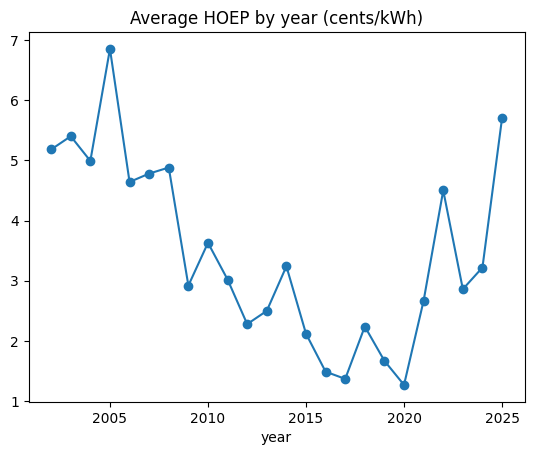

In [13]:
query = """
SELECT year,
       ROUND(AVG(price_cents), 2) AS avg_price,
       ROUND(MIN(price_cents), 2) AS min_price,
       ROUND(MAX(price_cents), 2) AS max_price,
       SUM(CASE WHEN price_cents < 0 THEN 1 ELSE 0 END) AS negative_price_hours
FROM hourly
WHERE price_cents IS NOT NULL
GROUP BY year
ORDER BY year
"""
price = pd.read_sql(query, conn)
price.plot(x="year", y="avg_price", kind="line", marker="o", title="Average HOEP by year (cents/kWh)", legend=False)
price

In [14]:
query = """
SELECT date, ROUND(MAX(demand_mw)) AS peak_mw
FROM hourly
GROUP BY date
ORDER BY peak_mw DESC
LIMIT 10
"""
pd.read_sql(query, conn)

,date,peak_mw
0,2006-08-01,27005.0
1,2005-07-13,26160.0
2,2005-06-27,26157.0
3,2006-07-31,26092.0
4,2006-07-17,25898.0
5,2005-06-28,25861.0
6,2005-07-18,25857.0
7,2006-08-02,25816.0
8,2005-08-09,25816.0
9,2005-07-12,25808.0
